# Citywide Rainfall: Radar Data Test

**Author:** Muhammad Kaleem — Climate Module Lead  
**Project:** Plexa: Multi-Modal Smart City Digital Twin and Cascading Resilience Engine

---

> **Goal:** Check whether NOAA MRMS radar rainfall can replace the single Central Park station as the rainfall source for the Climate module.

---

## At a Glance

| | |
|:---|:---|
| **Data source** | NOAA MRMS, hourly multi-sensor rainfall estimate (Pass 2) |
| **Coverage** | Whole of NYC, on a grid of roughly 1 km squares |
| **Update rate** | Hourly, with about a one-hour delay |
| **Test event** | Hurricane Ida, September 1 to 2, 2021 |
| **Output of this notebook** | A confirmed citywide rainfall source, or a documented reason to switch |

---

## Why This Notebook Exists

The earlier notebooks measured rainfall at one point in Manhattan, while the 311 complaints cover all five boroughs. That mismatch adds noise to the flood signal. Radar rainfall covers the same area as the complaints, so the two datasets can be compared on equal terms.

## Approach

1. Download the hourly radar files around Ida
2. Crop them to the NYC area
3. Plot the rainfall and confirm the storm appears where and when it should

Nothing larger is pulled until this test passes.

In [1]:
import os
import gzip
import shutil
import requests
from pathlib import Path

In [2]:
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
os.chdir(repo_root)
print("Working directory:", os.getcwd())

Working directory: /Users/macbookairm3/Documents/Plexa-A-Multi-Modal-Smart-City-Digital-Twin-and-Cascading-Resilience-Engine


In [3]:
import sys
print(sys.executable)

import cfgrib, eccodes, pandas, requests, xarray
print("cfgrib:", cfgrib.__version__)
print("eccodes:", eccodes.__version__)
print("All imports OK")

/opt/anaconda3/envs/plexa-climate/bin/python
cfgrib: 0.9.15.1
eccodes: 2.49.0
All imports OK


In [4]:
import re

RADAR_DIR = Path("data/raw/radar_ida")
RADAR_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "https://mtarchive.geol.iastate.edu/2021/09/02/mrms/ncep/"
    "MultiSensor_QPE_01H_Pass2/"
)
TARGET_HOURS = [f"{h:02d}" for h in range(0, 6)]

listing = requests.get(BASE_URL, timeout=60)
listing.raise_for_status()
available = re.findall(r'href="([^"]+\.grib2\.gz)"', listing.text)
print(f"{len(available)} files listed for 2021-09-02")

for hour in TARGET_HOURS:
    matches = [name for name in available if f"20210902-{hour}0000" in name]
    if not matches:
        print(f"{hour}:00 UTC: not found in archive")
        continue

    gz_name = matches[0]
    grib_path = RADAR_DIR / gz_name.replace(".gz", "")
    if grib_path.exists():
        print(f"{hour}:00 UTC: already downloaded")
        continue

    response = requests.get(BASE_URL + gz_name, stream=True, timeout=120)
    response.raise_for_status()
    gz_path = RADAR_DIR / gz_name
    with open(gz_path, "wb") as f:
        shutil.copyfileobj(response.raw, f)
    with gzip.open(gz_path, "rb") as f_in, open(grib_path, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)
    gz_path.unlink()
    print(f"{hour}:00 UTC: saved {grib_path.name}")

24 files listed for 2021-09-02
00:00 UTC: already downloaded
01:00 UTC: already downloaded
02:00 UTC: already downloaded
03:00 UTC: already downloaded
04:00 UTC: already downloaded
05:00 UTC: already downloaded


## Step 2: Crop to NYC and Check the Storm

Opens each radar file, crops the national grid to a box around the five boroughs, and reports the rainfall over that box for each hour. The peak hour is then plotted as a map. Ida's heaviest rain in Central Park fell at roughly 01:00 to 02:00 UTC, so the peak should appear there.

           hour_utc   mean_mm    max_mm  grid_cells
2021-09-02 00:00:00 18.034212 58.599998        2537
2021-09-02 01:00:00 25.688570 81.800003        2537
2021-09-02 02:00:00 41.589123 84.400002        2537
2021-09-02 03:00:00 23.055775 65.000000        2537
2021-09-02 04:00:00  9.420654 20.200001        2537
2021-09-02 05:00:00  3.273394 11.400000        2537


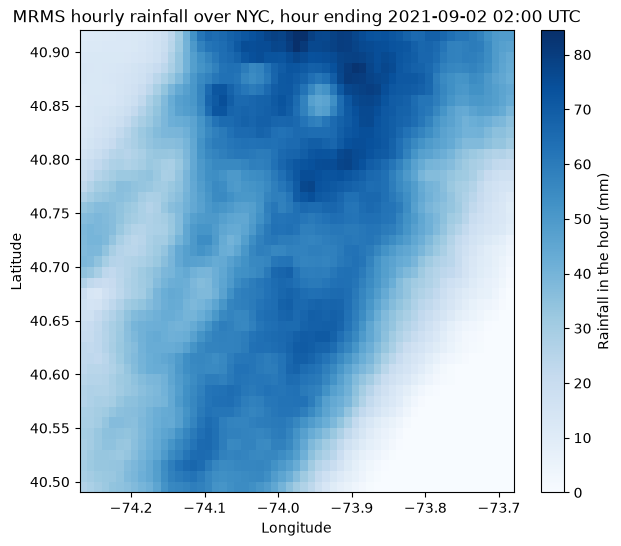

In [5]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

NYC_LAT = (40.49, 40.92)
NYC_LON = (-74.27, -73.68)
LON_MIN, LON_MAX = (lon % 360 for lon in NYC_LON)


def load_nyc_hour(path):
    ds = xr.open_dataset(path, engine="cfgrib", backend_kwargs={"indexpath": ""})
    rain = ds[list(ds.data_vars)[0]].sortby("latitude")
    rain = rain.sel(
        latitude=slice(*NYC_LAT),
        longitude=slice(LON_MIN, LON_MAX),
    )
    return rain.where(rain >= 0)


hours = {}
rows = []
for path in sorted(RADAR_DIR.glob("*.grib2")):
    rain = load_nyc_hour(path)
    timestamp = pd.to_datetime(rain.valid_time.values)
    hours[timestamp] = rain
    rows.append({
        "hour_utc": timestamp,
        "mean_mm": float(rain.mean()),
        "max_mm": float(rain.max()),
        "grid_cells": int(rain.count()),
    })

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

peak_time = summary.loc[summary["max_mm"].idxmax(), "hour_utc"]
peak = hours[peak_time]

fig, ax = plt.subplots(figsize=(7, 6))
mesh = ax.pcolormesh(
    peak.longitude - 360, peak.latitude, peak.values, cmap="Blues", shading="auto"
)
fig.colorbar(mesh, ax=ax, label="Rainfall in the hour (mm)")
ax.set_title(f"MRMS hourly rainfall over NYC, hour ending {peak_time:%Y-%m-%d %H:%M} UTC")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

## Result

The radar test passed. For the hour ending 02:00 UTC on September 2, 2021, the mean rainfall across the NYC crop was 41.6 mm and the maximum grid square reached 84.4 mm. Rainfall built through the evening of September 1 and fell away by 05:00 UTC, matching the known timing of the storm. All six hourly files covered the same 2,537 grid squares with no missing data, and the map shows a heavy north-south band with a much drier southeast corner, a spatial pattern the Central Park station cannot capture.

Limitations: the crop is a rectangle that includes parts of New Jersey and open water, so borough-level values will need boundary masks. Radar rainfall is an estimate calibrated against gauges, not a direct measurement.

Decision: MRMS Pass 2 radar is adopted as the citywide rainfall source for the Climate module.